# Влияние `var_smoothing` в Gaussian Naive Bayes

**Цель:** выяснить, что делает параметр `var_smoothing` в `sklearn.naive_bayes.GaussianNB`, зачем он нужен и как его значение влияет на качество классификации и на предсказанные вероятности.

**План:**
1. Как устроен GaussianNB и где в нём `var_smoothing`.
2. Маленький численный пример: что ломается без сглаживания.
3. Перебор `var_smoothing` на четырёх датасетах (accuracy и log loss).
4. Почему на `digits` сглаживание так сильно помогает.
5. Зависимость от масштаба признаков (`wine` с и без `StandardScaler`).
6. Как сглаживание меняет уверенность модели.
7. Подбор `var_smoothing` через `GridSearchCV` с честной оценкой.
8. Выводы.

## 1. Теория

GaussianNB считает, что внутри каждого класса $c$ признаки независимы и распределены нормально:

$$P(x_j \mid y=c) = \frac{1}{\sqrt{2\pi\sigma^2_{cj}}}\exp\left(-\frac{(x_j-\mu_{cj})^2}{2\sigma^2_{cj}}\right)$$

Класс выбирается по максимуму $\log P(y=c) + \sum_j \log P(x_j \mid y=c)$.

Проблема: если у какого-то признака внутри класса дисперсия $\sigma^2_{cj}=0$ (или почти 0), то деление на неё даёт бесконечность. Любое отклонение $x_j$ от $\mu_{cj}$ «убивает» этот класс целиком, даже если остальные признаки идеально подходят.

Поэтому sklearn добавляет ко всем дисперсиям одну и ту же константу:

$$\varepsilon = \texttt{var\_smoothing}\cdot \max_j \operatorname{Var}(X_{:,j}), \qquad \sigma^2_{cj} \leftarrow \sigma^2_{cj} + \varepsilon$$

Значение по умолчанию - `1e-9`. Важно: $\varepsilon$ берётся от **максимальной** дисперсии среди всех признаков. Значит, эффект параметра зависит от масштаба признаков (это проверим в разделе 5).

Интуиция: `var_smoothing` работает как регуляризация. Малое значение - модель доверяет оценённым дисперсиям и выдаёт «острые» распределения. Большое значение - все гауссианы расширяются, модель становится менее уверенной, а при очень большом значении перестаёт различать классы.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_wine, load_breast_cancer, load_digits
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import (StratifiedKFold, cross_validate, GridSearchCV,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Численный пример

Два класса, два признака. В классе 0 первый признак всегда равен 1.0, то есть его дисперсия внутри класса равна нулю.

In [4]:
X_toy = np.array([[1.0, 0.0], [1.0, 0.2], [1.0, 0.4],    # класс 0
                  [2.0, 1.0], [3.0, 1.2], [4.0, 1.4]])   # класс 1
y_toy = np.array([0, 0, 0, 1, 1, 1])

# Точка почти совпадает с классом 0: x1 = 1.01 (чуть-чуть мимо 1.0), x2 = 0.2 (ровно центр класса 0)
x_new = np.array([[1.01, 0.2]])

for vs in [0.0, 1e-9, 1e-2]:
    m = GaussianNB(var_smoothing=vs).fit(X_toy, y_toy)
    print(f"var_smoothing={vs:<6g} epsilon={m.epsilon_:.2e}  "
          f"дисперсии класса 0: {m.var_[0].round(4)}  "
          f"P(класс 0 | x_new) = {m.predict_proba(x_new)[0, 0]:.4f}")

var_smoothing=0      epsilon=0.00e+00  дисперсии класса 0: [0.     0.0267]  P(класс 0 | x_new) = nan
var_smoothing=1e-09  epsilon=1.33e-09  дисперсии класса 0: [0.     0.0267]  P(класс 0 | x_new) = 0.0000
var_smoothing=0.01   epsilon=1.33e-02  дисперсии класса 0: [0.0133 0.04  ]  P(класс 0 | x_new) = 1.0000


Разбор по шагам (для `var_smoothing=1e-9`):

- $\max_j \operatorname{Var}(X_{:,j}) = \operatorname{Var}(1,1,1,2,3,4) \approx 1.33$, значит $\varepsilon \approx 1.33\cdot10^{-9}$.
- Для класса 0 по первому признаку $\sigma^2 \approx 1.33\cdot10^{-9}$, отклонение $0.01$. Тогда штраф в лог-правдоподобии $\frac{0.01^2}{2\cdot1.33\cdot10^{-9}} \approx 37\,500$.
- Это перевешивает всё остальное, и модель на 100% уверена в классе 1, хотя точка явно похожа на класс 0.
- При `var_smoothing=0` получаем деление на ноль и `nan`.
- При `var_smoothing=1e-2`: $\varepsilon \approx 0.013$, штраф $\approx 0.004$, и модель правильно выбирает класс 0.

Вывод: сглаживание нужно не только для численной устойчивости. Оно защищает от переобучения на признаках, которые в обучающей выборке случайно оказались константными внутри класса.

## 3. Перебор `var_smoothing` на четырёх датасетах

Берём 4 встроенных датасета sklearn. Для каждого значения `var_smoothing` из сетки $10^{-12}\ldots10^{2}$ считаем на 5-кратной стратифицированной кросс-валидации:
- **accuracy** - доля правильных ответов;
- **log loss** - качество предсказанных вероятностей (чем меньше, тем лучше).

Признаки стандартизуем (`StandardScaler` внутри `Pipeline`, чтобы не было утечки данных). Влияние масштаба отдельно разберём в разделе 5.

In [5]:
datasets = {
    "iris": load_iris(return_X_y=True),
    "wine": load_wine(return_X_y=True),
    "breast_cancer": load_breast_cancer(return_X_y=True),
    "digits": load_digits(return_X_y=True),
}
for name, (X, y) in datasets.items():
    print(f"{name:14s} объектов={X.shape[0]:5d}  признаков={X.shape[1]:3d}  классов={len(np.unique(y))}")

grid = np.logspace(-12, 2, 29)

def sweep(X, y, scale=True):
    rows = []
    for vs in grid:
        model = GaussianNB(var_smoothing=vs)
        if scale:
            model = make_pipeline(StandardScaler(), model)
        r = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "neg_log_loss"])
        rows.append({"var_smoothing": vs,
                     "accuracy": r["test_accuracy"].mean(),
                     "accuracy_std": r["test_accuracy"].std(),
                     "log_loss": -r["test_neg_log_loss"].mean()})
    return pd.DataFrame(rows)

results = {name: sweep(X, y) for name, (X, y) in datasets.items()}

iris           объектов=  150  признаков=  4  классов=3
wine           объектов=  178  признаков= 13  классов=3
breast_cancer  объектов=  569  признаков= 30  классов=2
digits         объектов= 1797  признаков= 64  классов=10


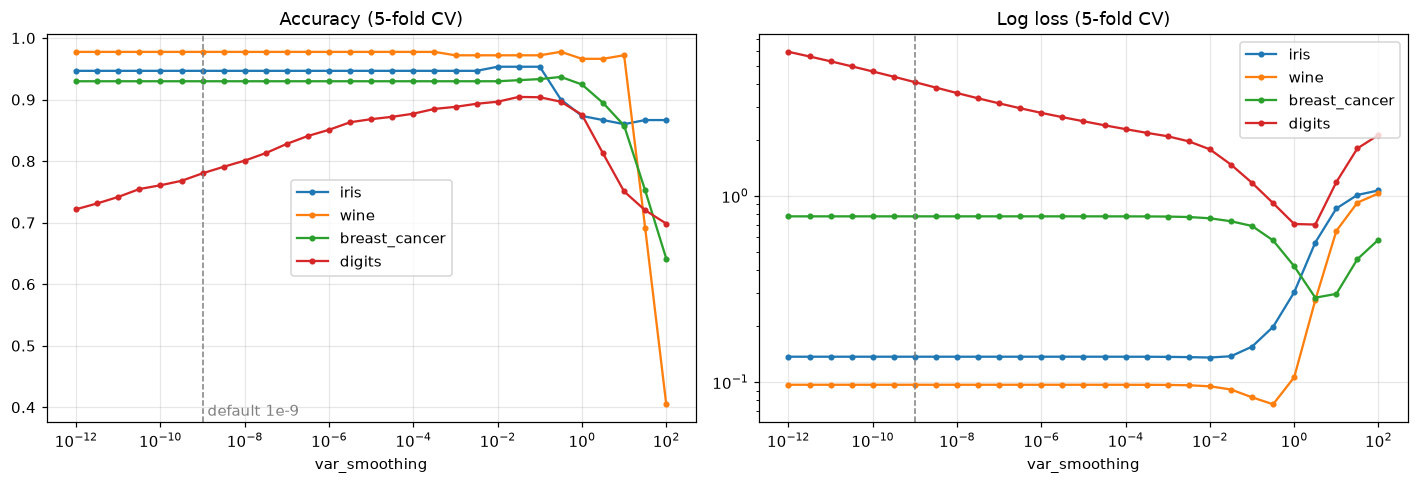

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, df in results.items():
    axes[0].plot(df.var_smoothing, df.accuracy, marker="o", ms=3, label=name)
    axes[1].plot(df.var_smoothing, df.log_loss, marker="o", ms=3, label=name)
for ax, title in zip(axes, ["Accuracy (5-fold CV)", "Log loss (5-fold CV)"]):
    ax.set_xscale("log"); ax.axvline(1e-9, color="gray", ls="--", lw=1)
    ax.set_xlabel("var_smoothing"); ax.set_title(title); ax.grid(alpha=.3); ax.legend()
axes[1].set_yscale("log")
axes[0].text(1.3e-9, axes[0].get_ylim()[0] + 0.01, "default 1e-9", color="gray")
plt.tight_layout(); plt.show()

In [7]:
summary = []
for name, df in results.items():
    default = df.iloc[(np.abs(np.log10(df.var_smoothing) + 9)).argmin()]
    best_acc = df.loc[df.accuracy.idxmax()]
    best_ll = df.loc[df.log_loss.idxmin()]
    summary.append({"датасет": name,
                    "acc при 1e-9": round(default.accuracy, 3),
                    "лучшая acc": round(best_acc.accuracy, 3),
                    "vs для лучшей acc": f"{best_acc.var_smoothing:.0e}",
                    "logloss при 1e-9": round(default.log_loss, 3),
                    "лучший logloss": round(best_ll.log_loss, 3),
                    "vs для лучшего logloss": f"{best_ll.var_smoothing:.0e}"})
summary = pd.DataFrame(summary)
print(summary.to_string(index=False))

      датасет  acc при 1e-9  лучшая acc vs для лучшей acc  logloss при 1e-9  лучший logloss vs для лучшего logloss
         iris         0.947       0.953             1e-02             0.137           0.136                  1e-02
         wine         0.977       0.978             3e-01             0.097           0.076                  3e-01
breast_cancer         0.930       0.937             3e-01             0.777           0.284                  3e+00
       digits         0.780       0.904             3e-02             4.082           0.702                  3e+00


Что видно:

- **iris, wine** - почти ничего не меняется вплоть до `var_smoothing≈0.1`. Внутри классов дисперсии признаков нормальные, добавка $\varepsilon$ на их фоне незаметна. При `var_smoothing ≥ 1` гауссианы становятся слишком широкими, качество падает.
- **breast_cancer** - accuracy почти не меняется, а log loss заметно улучшается при больших значениях. Наивное предположение о независимости признаков здесь сильно нарушено (многие признаки коррелированы). Из-за этого модель выдаёт «уверенные» вероятности, близкие к 0 и 1, и иногда ошибается. Сглаживание делает её скромнее.
- **digits** - самый сильный эффект: accuracy растёт с ~0.78 при дефолте до ~0.90, log loss падает в несколько раз. Почему - ниже.
- Оптимумы для accuracy и log loss **не совпадают**: для вероятностей обычно нужно большее сглаживание, чем для меток.

## 4. Почему на `digits` сглаживание так важно

`digits` - картинки 8×8, признак - яркость пикселя (0-16). Многие пиксели (края картинки) у конкретной цифры почти всегда равны 0. Внутри класса их дисперсия равна нулю, и возникает ровно та ситуация из численного примера.

In [8]:
X_d, y_d = datasets["digits"]
zero_var = np.array([(X_d[y_d == c].var(axis=0) == 0).sum() for c in range(10)])
print("Число пикселей с нулевой дисперсией внутри класса (из 64):")
print(dict(zip(range(10), zero_var.tolist())))

# Пиксели, которые в классе почти всегда 0, но в отдельных картинках не равны 0
rare = np.array([((X_d[y_d == c] > 0).mean(axis=0) > 0) & ((X_d[y_d == c] > 0).mean(axis=0) < 0.05)
                 for c in range(10)]).sum(axis=1)
print("\nПиксели, ненулевые меньше чем в 5% картинок класса:")
print(dict(zip(range(10), rare.tolist())))

Число пикселей с нулевой дисперсией внутри класса (из 64):
{0: 16, 1: 12, 2: 9, 3: 10, 4: 11, 5: 13, 6: 15, 7: 15, 8: 12, 9: 10}

Пиксели, ненулевые меньше чем в 5% картинок класса:
{0: 4, 1: 4, 2: 8, 3: 7, 4: 9, 5: 4, 6: 5, 7: 3, 8: 4, 9: 5}


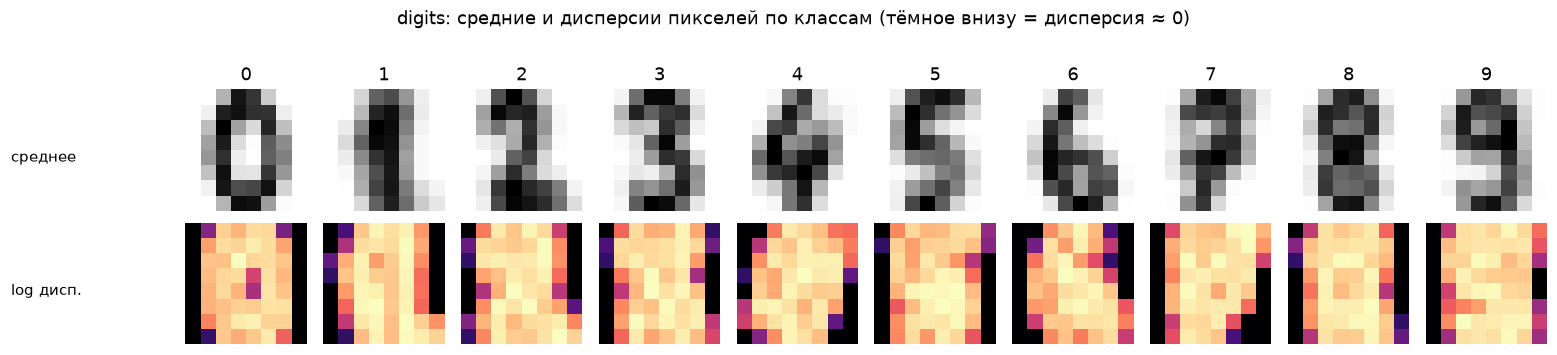

In [9]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for c in range(10):
    Xc = X_d[y_d == c]
    axes[0, c].imshow(Xc.mean(axis=0).reshape(8, 8), cmap="gray_r")
    axes[1, c].imshow(np.log10(Xc.var(axis=0) + 1e-3).reshape(8, 8), cmap="magma")
    axes[0, c].set_title(str(c)); [a.axis("off") for a in axes[:, c]]
axes[0, 0].text(-12, 4, "среднее", va="center"); axes[1, 0].text(-12, 4, "log дисп.", va="center")
plt.suptitle("digits: средние и дисперсии пикселей по классам (тёмное внизу = дисперсия ≈ 0)", y=1.02)
plt.tight_layout(); plt.show()

Если в тестовой картинке "пятёрки" случайно засветился пиксель, который у всех обучающих пятёрок был нулевым, то при малом $\varepsilon$ класс "5" получает огромный штраф и проигрывает, даже если остальные 63 пикселя совпадают идеально. Большее `var_smoothing` делает такие пиксели "терпимыми" к шуму. Поэтому на данных с разреженными/почти константными признаками дефолтное значение `1e-9` явно слишком мало.

## 5. Зависимость от масштаба признаков

Напомню: $\varepsilon = \texttt{var\_smoothing}\cdot\max_j\operatorname{Var}(X_{:,j})$. В `wine` признаки имеют очень разный масштаб: `proline` - сотни/тысячи, `hue` - около единицы. Значит $\varepsilon$ определяется `proline`, и для "маленьких" признаков добавка оказывается огромной.

max дисперсия: 98610 (proline)
min дисперсия: 0.0154 (nonflavanoid_phenols)
отношение: 6.4e+06


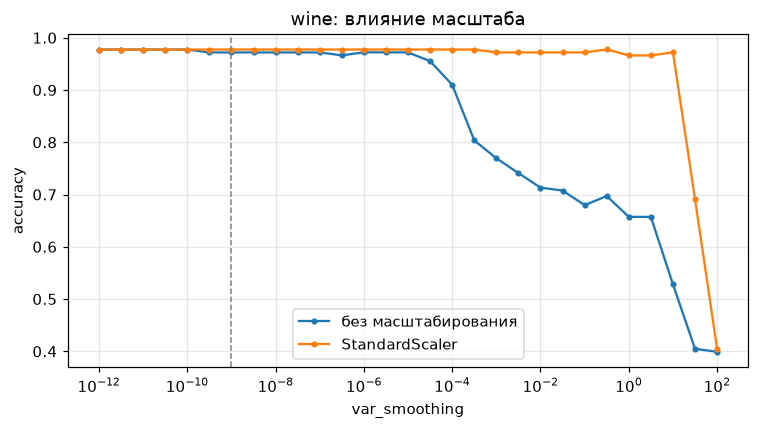

In [10]:
X_w, y_w = datasets["wine"]
names_w = load_wine().feature_names
v = X_w.var(axis=0)
print(f"max дисперсия: {v.max():.0f} ({names_w[v.argmax()]})")
print(f"min дисперсия: {v.min():.4f} ({names_w[v.argmin()]})")
print(f"отношение: {v.max() / v.min():.1e}")

wine_raw = sweep(X_w, y_w, scale=False)
wine_scaled = results["wine"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(wine_raw.var_smoothing, wine_raw.accuracy, marker="o", ms=3, label="без масштабирования")
ax.plot(wine_scaled.var_smoothing, wine_scaled.accuracy, marker="o", ms=3, label="StandardScaler")
ax.set_xscale("log"); ax.axvline(1e-9, color="gray", ls="--", lw=1)
ax.set_xlabel("var_smoothing"); ax.set_ylabel("accuracy"); ax.set_title("wine: влияние масштаба")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

Без масштабирования качество падает уже при `var_smoothing≈1e-4` (с 0.97 до ~0.9, а при `1e-3` - до ~0.77): $\varepsilon \approx 10^{-3}\cdot 10^5 = 100$, это намного больше дисперсии большинства признаков, и они перестают влиять на ответ. После `StandardScaler` все дисперсии ≈ 1, и параметр ведёт себя предсказуемо.

Сам по себе GaussianNB к масштабу инвариантен (каждый признак нормируется своей $\sigma$), **но `var_smoothing` - нет**. Поэтому подбирать его без масштабирования рискованно: «хорошее» значение для одного набора единиц измерения будет плохим для другого.

## 6. Влияние на уверенность модели

Посмотрим, как меняется средняя вероятность предсказанного класса (уверенность) отдельно для правильных и ошибочных ответов на `digits`.

In [11]:
Xtr, Xte, ytr, yte = train_test_split(X_d, y_d, test_size=0.3, stratify=y_d, random_state=RANDOM_STATE)
rows = []
for vs in [1e-9, 1e-5, 1e-2, 1e-1, 1, 10]:
    m = make_pipeline(StandardScaler(), GaussianNB(var_smoothing=vs)).fit(Xtr, ytr)
    p = m.predict_proba(Xte); pred = p.argmax(1); conf = p.max(1); ok = pred == yte
    rows.append({"var_smoothing": vs, "accuracy": ok.mean(),
                 "увер. (верные)": conf[ok].mean(), "увер. (ошибки)": conf[~ok].mean(),
                 "доля ответов с p>0.999": (conf > 0.999).mean(),
                 "log_loss": log_loss(yte, p)})
conf_df = pd.DataFrame(rows)
print(conf_df.to_string(index=False, formatters={"var_smoothing": "{:.0e}".format}, float_format="{:.3f}".format))

var_smoothing  accuracy  увер. (верные)  увер. (ошибки)  доля ответов с p>0.999  log_loss
        1e-09     0.772           0.995           0.979                   0.878     4.595
        1e-05     0.839           0.993           0.949                   0.881     3.049
        1e-02     0.891           0.995           0.956                   0.893     2.065
        1e-01     0.889           0.996           0.911                   0.835     1.392
        1e+00     0.880           0.954           0.816                   0.413     0.855
        1e+01     0.787           0.440           0.306                   0.006     1.187


При дефолтном `1e-9` модель почти всегда уверена на ~100%, **в том числе когда ошибается**. Отсюда огромный log loss. С ростом `var_smoothing` уверенность в ошибочных ответах падает быстрее, чем в правильных, и вероятности становятся осмысленнее. При слишком большом значении (10) модель размазывает вероятности по всем классам, и падает уже и accuracy.

## 7. Подбор `var_smoothing` через GridSearchCV

На практике параметр подбирают по сетке на кросс-валидации. Чтобы оценка качества была честной (не подглядывать в тест при выборе параметра), используем вложенную кросс-валидацию: внутренний цикл выбирает `var_smoothing`, внешний оценивает качество всей процедуры.

In [12]:
param_grid = {"gaussiannb__var_smoothing": np.logspace(-12, 2, 29)}
outer = StratifiedKFold(5, shuffle=True, random_state=0)
inner = StratifiedKFold(5, shuffle=True, random_state=1)

rows = []
for name, (X, y) in datasets.items():
    pipe = make_pipeline(StandardScaler(), GaussianNB())
    gs = GridSearchCV(pipe, param_grid, cv=inner, scoring="accuracy")
    nested = cross_val_score(gs, X, y, cv=outer, scoring="accuracy")
    default = cross_val_score(pipe, X, y, cv=outer, scoring="accuracy")
    best_vs = GridSearchCV(pipe, param_grid, cv=inner, scoring="accuracy").fit(X, y) \
        .best_params_["gaussiannb__var_smoothing"]
    rows.append({"датасет": name,
                 "default (1e-9)": f"{default.mean():.3f} ± {default.std():.3f}",
                 "GridSearch (nested CV)": f"{nested.mean():.3f} ± {nested.std():.3f}",
                 "выбранный var_smoothing": f"{best_vs:.0e}"})
print(pd.DataFrame(rows).to_string(index=False))

      датасет default (1e-9) GridSearch (nested CV) выбранный var_smoothing
         iris  0.960 ± 0.013          0.960 ± 0.013                   1e-12
         wine  0.972 ± 0.000          0.966 ± 0.011                   1e-12
breast_cancer  0.930 ± 0.012          0.935 ± 0.016                   3e-01
       digits  0.786 ± 0.032          0.905 ± 0.011                   1e-01


- На **digits** подбор даёт +12 п.п. accuracy, и это честная оценка: параметр выбирался без использования внешних тестовых фолдов.
- На **iris** и **wine** выигрыша нет. Кривая качества там плоская, все малые значения дают одинаковый результат, и `GridSearchCV` при равенстве просто берёт первое значение сетки (`1e-12`). Небольшое отличие на wine (0.966 против 0.972) - шум от выбора параметра на маленькой выборке.
- На **breast_cancer** небольшой прирост, в пределах разброса.

## 8. Выводы

1. `var_smoothing` добавляет ко всем дисперсиям $\varepsilon = \texttt{var\_smoothing}\cdot\max_j\operatorname{Var}(X_j)$. Без этого GaussianNB ломается на признаках с нулевой дисперсией внутри класса (деление на 0, `nan`), а при слишком малом $\varepsilon$ один «неудачный» признак может перечеркнуть все остальные.
2. Это регуляризация: малое значение даёт острые и самоуверенные распределения, большое - сглаженные и осторожные, а слишком большое - модель перестаёт различать классы.
3. Насколько сильно параметр влияет, зависит от данных:
   - на «хороших» непрерывных признаках (iris, wine) результат почти не меняется в диапазоне $10^{-12}\ldots10^{-1}$;
   - на данных с разреженными/почти константными признаками (digits) подбор даёт +10 п.п. accuracy и кратно меньший log loss;
   - на данных с коррелированными признаками (breast_cancer) он слабо влияет на accuracy, но заметно улучшает вероятности.
4. Оптимум по log loss обычно больше, чем по accuracy. Если вероятности модели важны, подбирать параметр стоит по log loss.
5. Параметр **зависит от масштаба признаков**, хотя сам GaussianNB - нет. Перед подбором `var_smoothing` признаки лучше стандартизовать.
6. Подбирать по логарифмической сетке через `GridSearchCV`. Дефолт `1e-9` по сути только защищает от деления на ноль и регуляризацией не является.